# Thyroid Disease Classification

Predict thyroid status from routine blood tests and clinical flags, using a random forest.

**Scope note on the target.** The brief asks for three classes (negative / hypothyroid /
hyperthyroid). This dataset's only label column is `binaryClass`, which has two values. Class `1`
shows high TSH with low TT4 and low FTI, which is hypothyroidism; there is no hyperthyroid group
in the file, and it cannot be recovered from it. So this notebook models the binary problem:

| label | meaning | n | share |
|---|---|---|---|
| `0` | negative | 3480 | 92.3% |
| `1` | hypothyroid | 291 | 7.7% |

At 7.7% positives, **accuracy is not a usable metric** -- always predicting "negative" scores 92.3%.
Evaluation below centres on recall and precision for the hypothyroid class.

## 1. Setup

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

# Validated two-series categorical palette (light surface).
NEG, POS = "#2a78d6", "#eb6834"
SURFACE, INK, INK2 = "#fcfcfb", "#0b0b0b", "#52514e"
BLUES = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#c9c8c3", "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.titlepad": 12, "axes.labelsize": 9, "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "xtick.direction": "out", "ytick.direction": "out",
    "grid.color": "#e8e7e3", "grid.linewidth": 0.8, "axes.grid": True, "axes.grid.axis": "y",
    "legend.frameon": False, "legend.fontsize": 9, "legend.labelcolor": INK2,
    "figure.dpi": 110, "font.size": 10, "lines.linewidth": 2,
})

CSV = "../dataset/cleaned_dataset_Thyroid1.csv"
TARGET = "binaryClass"
CONTINUOUS = ["age", "TSH", "TT4", "T4U", "FTI"]
MEASURED = ["TSH measured", "T3 measured", "TT4 measured", "T4U measured", "FTI measured"]
CLASS_NAMES = ["negative", "hypothyroid"]

## 2. Load and first look

In [2]:
df = pd.read_csv(CSV)
print(f"shape: {df.shape}")
print(f"null cells: {df.isna().sum().sum()}")
print(f"exact duplicate rows: {df.duplicated().sum()}")
df.head()

shape: (3771, 26)
null cells: 0
exact duplicate rows: 63


,age,sex,on thyroxine,query on thyroxine,on antithyroid medication,sick,pregnant,thyroid surgery,I131 treatment,query hypothyroid,...,TSH measured,TSH,T3 measured,TT4 measured,TT4,T4U measured,T4U,FTI measured,FTI,binaryClass
0,41.0,0.0,0,0,0,0,0,0,0,0,...,1,1.30,1,1,125.0,1.0,1.140,1,109.000000,0
1,23.0,0.0,0,0,0,0,0,0,0,0,...,1,4.10,1,1,102.0,0.0,0.995,0,110.469649,0
2,46.0,1.0,0,0,0,0,0,0,0,0,...,1,0.98,0,1,109.0,1.0,0.910,1,120.000000,0
3,70.0,0.0,1,0,0,0,0,0,0,0,...,1,0.16,1,1,175.0,0.0,0.995,0,110.469649,0
4,70.0,0.0,0,0,0,0,0,0,0,0,...,1,0.72,1,1,61.0,1.0,0.870,1,70.000000,0


In [3]:
counts = df[TARGET].value_counts().sort_index()
pd.DataFrame({"n": counts, "pct": (100 * counts / len(df)).round(2)}).rename(
    index={0: "negative", 1: "hypothyroid"}
)

,n,pct
binaryClass,,
negative,3480,92.28
hypothyroid,291,7.72


## 3. Exploratory analysis

### 3.1 Class balance

The imbalance is the single most important fact about this problem, so it goes first.

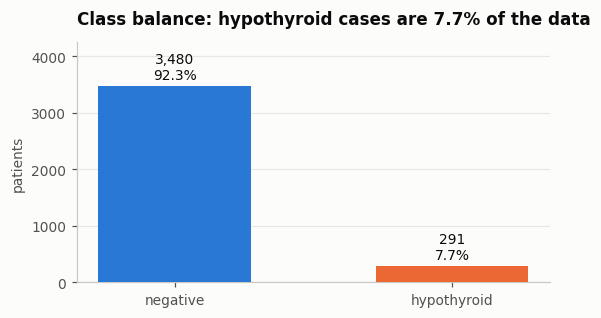

In [4]:
fig, ax = plt.subplots(figsize=(5.2, 3.0))
bars = ax.bar(CLASS_NAMES, counts.values, color=[NEG, POS], width=0.55, zorder=3)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 60, f"{v:,}\n{100*v/len(df):.1f}%",
            ha="center", va="bottom", fontsize=9, color=INK)
ax.set_ylim(0, counts.max() * 1.22)
ax.set_ylabel("patients")
ax.set_title("Class balance: hypothyroid cases are 7.7% of the data")
ax.spines["bottom"].set_color("#c9c8c3")
plt.tight_layout()
plt.show()

### 3.2 The missing values were mean-imputed, and the `measured` flags mark them

This file is a "cleaned" export. Nothing is null -- but every row where a `X measured` flag is `0`
carries one single repeated value in the matching value column, and that value equals the column
mean. The blood test was never run; the number is a fill.

In [5]:
rows = []
for flag, val in [("TSH measured", "TSH"), ("TT4 measured", "TT4"),
                  ("T4U measured", "T4U"), ("FTI measured", "FTI")]:
    unmeasured = df.loc[df[flag] == 0, val]
    rows.append({"feature": val, "n_unmeasured": len(unmeasured),
                 "distinct_values": unmeasured.nunique(),
                 "fill_value": round(unmeasured.iloc[0], 6),
                 "column_mean": round(df[val].mean(), 6)})
imputation = pd.DataFrame(rows).set_index("feature")
print(imputation.to_string())

sex_fill = sorted(set(df["sex"]) - {0.0, 1.0})
print(f"\nsex: {(~df['sex'].isin([0.0, 1.0])).sum()} rows imputed with {sex_fill}")
print("\n'T3 measured' exists but there is no T3 value column -- the flag survived, "
      "the measurement did not.")

         n_unmeasured  distinct_values  fill_value  column_mean
feature                                                        
TSH               369                1    5.086766     5.087823
TT4               231                1  108.319345   108.316778
T4U               387                1    0.995000     0.994964
FTI               385                1  110.469649   110.471364

sex: 150 rows imputed with [0.3152954168967421]

'T3 measured' exists but there is no T3 value column -- the flag survived, the measurement did not.


Left alone this is a problem in two ways: the fills were computed over the whole file, so any
train/test split leaks global means into the test rows, and a fake value at the class mean is
indistinguishable from a real reading at the class mean. Section 4 reverses it.

### 3.3 Blood tests by class

TSH spans five orders of magnitude, so it is drawn on a log axis. These three panels are the
clinical signature of hypothyroidism: TSH up, TT4 and FTI down.

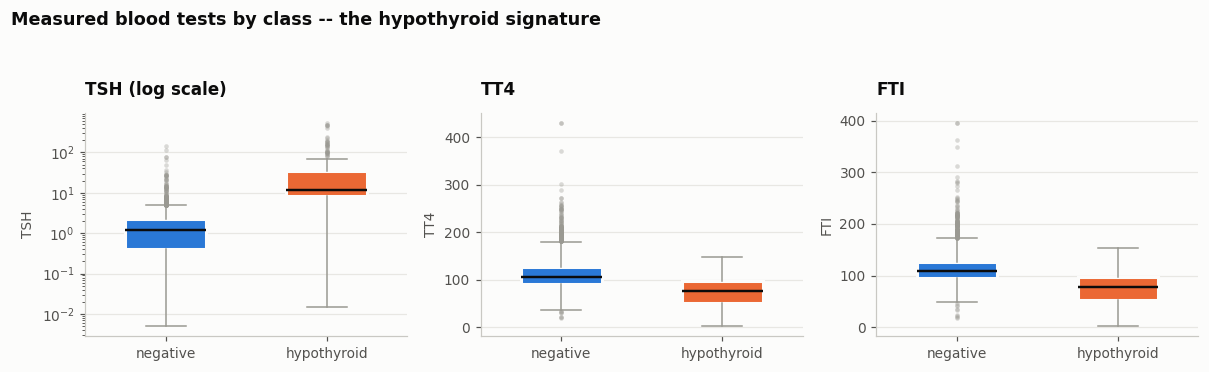

binaryClass,negative,hypothyroid
age,54.00,55.00
TSH,1.40,12.00
TT4,108.00,77.00
T4U,0.99,0.99
FTI,110.47,81.00


In [6]:
panels = [("TSH", "TSH measured", True), ("TT4", "TT4 measured", False), ("FTI", "FTI measured", False)]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))

for ax, (col, flag, logscale) in zip(axes, panels):
    sub = df[df[flag] == 1]  # measured rows only, so fills don't distort the shape
    data = [sub.loc[sub[TARGET] == k, col].values for k in (0, 1)]
    parts = ax.boxplot(data, labels=CLASS_NAMES, widths=0.5, patch_artist=True,
                       medianprops=dict(color=INK, linewidth=1.6),
                       whiskerprops=dict(color="#9a9992"), capprops=dict(color="#9a9992"),
                       flierprops=dict(marker="o", markersize=3, markerfacecolor="#9a9992",
                                       markeredgecolor="none", alpha=0.35))
    for patch, c in zip(parts["boxes"], [NEG, POS]):
        patch.set_facecolor(c)
        patch.set_edgecolor(SURFACE)
        patch.set_linewidth(2)
    if logscale:
        ax.set_yscale("log")
    ax.set_title(f"{col}" + (" (log scale)" if logscale else ""))
    ax.set_ylabel(col)
    ax.spines["bottom"].set_color("#c9c8c3")

fig.suptitle("Measured blood tests by class -- the hypothyroid signature", x=0.005, ha="left",
             fontsize=11.5, fontweight="semibold", color=INK)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

df.groupby(TARGET)[CONTINUOUS].median().rename(index={0: "negative", 1: "hypothyroid"}).T.round(2)

### 3.4 Clinical flags: how often each is positive within each class

In [7]:
flags = [c for c in df.columns if c not in CONTINUOUS + [TARGET, "sex"]]
rates = pd.DataFrame({
    "negative_pct": (100 * df.loc[df[TARGET] == 0, flags].eq(1).mean()).round(2),
    "hypothyroid_pct": (100 * df.loc[df[TARGET] == 1, flags].eq(1).mean()).round(2),
    "n_positive": df[flags].eq(1).sum(),
}).sort_values("n_positive", ascending=False)
rates["lift"] = (rates.hypothyroid_pct - rates.negative_pct).round(2)
rates

,negative_pct,hypothyroid_pct,n_positive,lift
TT4 measured,93.51,98.28,3540,4.77
TSH measured,89.40,100.00,3402,10.60
FTI measured,89.66,91.41,3386,1.75
T4U measured,89.60,91.41,3384,1.81
T3 measured,79.22,84.19,3002,4.97
on thyroxine,13.07,3.09,464,-9.98
query hyperthyroid,6.38,5.15,237,-1.23
query hypothyroid,5.60,13.40,234,7.80
psych,5.06,2.75,184,-2.31
sick,3.91,3.78,147,-0.13


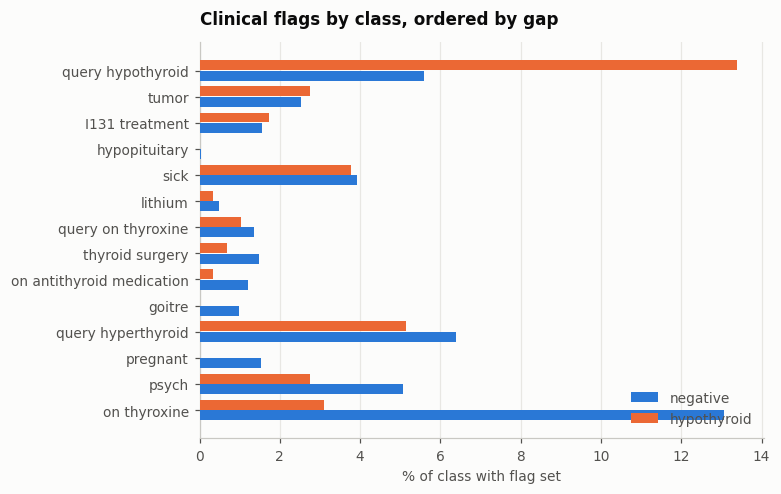

In [8]:
plot_flags = rates.drop(index=MEASURED).sort_values("lift")
y = np.arange(len(plot_flags))
fig, ax = plt.subplots(figsize=(7.2, 4.6))
ax.barh(y - 0.2, plot_flags.negative_pct, height=0.38, color=NEG, label="negative", zorder=3)
ax.barh(y + 0.2, plot_flags.hypothyroid_pct, height=0.38, color=POS, label="hypothyroid", zorder=3)
ax.set_yticks(y, plot_flags.index)
ax.set_xlabel("% of class with flag set")
ax.set_title("Clinical flags by class, ordered by gap")
ax.grid(axis="x", zorder=0)
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
ax.spines["left"].set_color("#c9c8c3")
plt.tight_layout()
plt.show()

Two things to read off this. `query hypothyroid` -- the referring clinician already suspecting
it -- is the strongest single flag. And `query hyperthyroid` is *slightly more* common among the
negatives, which is the clearest evidence that it is a referral reason and not a usable
hyperthyroid label.

## 4. Cleaning

Four steps, each with a reason:

1. **Drop 63 exact duplicate rows.** With 25 columns including five continuous measurements,
   identical rows are export artifacts rather than coincidence. Dropping them *before* the split
   also stops the same patient landing in train and test.
2. **Reverse the mean imputation** -- restore the fills to `NaN`. Scikit-learn's random forest
   handles missing values natively (1.4+), and the `measured` flags are kept, so the model still
   knows a test was skipped. It just no longer sees a fabricated number.
3. **Drop `hypopituitary`** -- one positive case in 3771 rows. It cannot generalise.
4. **Keep the `measured` flags.** They carry real signal: `TSH measured` is 1 for 100% of
   hypothyroid patients vs 89.4% of negatives, because the diagnosis requires the test. That is
   a property of the referral process, and it is worth being explicit that the model can lean on
   it -- see the caveat in section 8.

In [9]:
clean = df.drop_duplicates().copy()
print(f"dropped {len(df) - len(clean)} duplicate rows -> {len(clean)} remain")

# Step 2: fills back to NaN.
for flag, val in [("TSH measured", "TSH"), ("TT4 measured", "TT4"),
                  ("T4U measured", "T4U"), ("FTI measured", "FTI")]:
    clean.loc[clean[flag] == 0, val] = np.nan
clean.loc[~clean["sex"].isin([0.0, 1.0]), "sex"] = np.nan

clean = clean.drop(columns=["hypopituitary"])

print(f"shape after cleaning: {clean.shape}")
print("\nmissing values now visible:")
print(clean.isna().sum()[lambda s: s > 0].to_string())
print(f"\nclass balance preserved: {clean[TARGET].value_counts().sort_index().to_dict()}")

dropped 63 duplicate rows -> 3708 remain
shape after cleaning: (3708, 25)

missing values now visible:
sex    148
TSH    307
TT4    169
T4U    325
FTI    323

class balance preserved: {0: 3417, 1: 291}


## 5. Train / test split

Stratified, so both sides keep the 7.7% positive rate. The test set is touched once, at evaluation.

In [10]:
X = clean.drop(columns=[TARGET])
y = clean[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f"train {X_train.shape}  positives {y_train.sum()} ({100*y_train.mean():.2f}%)")
print(f"test  {X_test.shape}  positives {y_test.sum()} ({100*y_test.mean():.2f}%)")

train (2966, 24)  positives 233 (7.86%)
test  (742, 24)  positives 58 (7.82%)


## 6. Random forest

`class_weight="balanced"` so the 7.7% minority is not simply ignored. Cross-validation on the
training folds first, to check the model is stable before spending the test set.

In [11]:
rf = RandomForestClassifier(
    n_estimators=500,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

cv = cross_validate(
    rf, X_train, y_train,
    cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
    scoring=["average_precision", "roc_auc", "recall", "precision", "f1"],
)
pd.DataFrame({k.replace("test_", ""): v for k, v in cv.items() if k.startswith("test_")}).agg(
    ["mean", "std"]
).T.round(4)

,mean,std
average_precision,0.9832,0.0124
roc_auc,0.9988,0.0007
recall,0.9914,0.0118
precision,0.8865,0.0356
f1,0.9356,0.0154


In [12]:
rf.fit(X_train, y_train)
proba = rf.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

print(classification_report(y_test, pred, target_names=CLASS_NAMES, digits=4))
print(f"ROC-AUC          {roc_auc_score(y_test, proba):.4f}")
print(f"Average precision {average_precision_score(y_test, proba):.4f}")

              precision    recall  f1-score   support

    negative     1.0000    0.9956    0.9978       684
 hypothyroid     0.9508    1.0000    0.9748        58

    accuracy                         0.9960       742
   macro avg     0.9754    0.9978    0.9863       742
weighted avg     0.9962    0.9960    0.9960       742

ROC-AUC          0.9997
Average precision 0.9961


## 7. Evaluation

### 7.1 Confusion matrix

For a screening test the bottom-left cell -- hypothyroid patients called negative -- is the
expensive error, so it is worth reading this matrix by row.

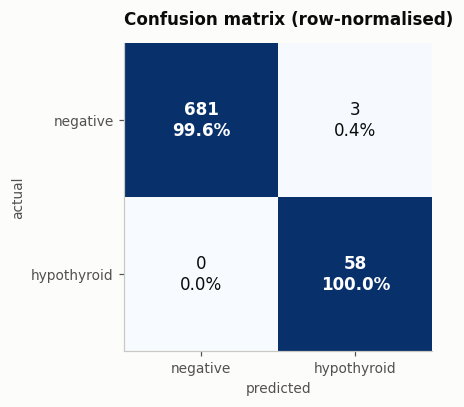

In [13]:
cm = confusion_matrix(y_test, pred)
fig, ax = plt.subplots(figsize=(4.4, 3.8))
ax.imshow(cm / cm.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
for i in range(2):
    for j in range(2):
        share = cm[i, j] / cm[i].sum()
        ax.text(j, i, f"{cm[i, j]}\n{share:.1%}", ha="center", va="center", fontsize=11,
                color="#ffffff" if share > 0.5 else INK,
                fontweight="semibold" if i == j else "normal")
ax.set_xticks([0, 1], CLASS_NAMES)
ax.set_yticks([0, 1], CLASS_NAMES)
ax.set_xlabel("predicted")
ax.set_ylabel("actual")
ax.set_title("Confusion matrix (row-normalised)")
ax.grid(False)
plt.tight_layout()
plt.show()

### 7.2 Precision-recall and ROC

With 7.7% positives the precision-recall curve is the honest one; ROC is shown beside it because
it is conventional, but its baseline is the diagonal while PR's baseline is the 0.077 positive rate.

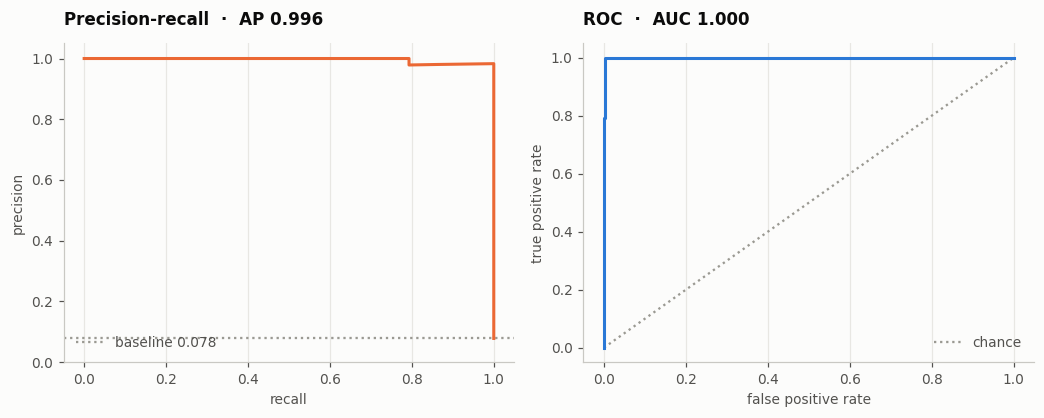

In [14]:
prec, rec, thr = precision_recall_curve(y_test, proba)
fpr, tpr, _ = roc_curve(y_test, proba)
ap, auc = average_precision_score(y_test, proba), roc_auc_score(y_test, proba)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.9))

ax1.plot(rec, prec, color=POS, zorder=3)
ax1.axhline(y_test.mean(), color="#9a9992", linestyle=":", linewidth=1.5,
            label=f"baseline {y_test.mean():.3f}")
ax1.set_xlabel("recall")
ax1.set_ylabel("precision")
ax1.set_title(f"Precision-recall  ·  AP {ap:.3f}")
ax1.set_ylim(0, 1.05)
ax1.legend(loc="lower left")

ax2.plot(fpr, tpr, color=NEG, zorder=3)
ax2.plot([0, 1], [0, 1], color="#9a9992", linestyle=":", linewidth=1.5, label="chance")
ax2.set_xlabel("false positive rate")
ax2.set_ylabel("true positive rate")
ax2.set_title(f"ROC  ·  AUC {auc:.3f}")
ax2.legend(loc="lower right")

for ax in (ax1, ax2):
    ax.grid(axis="both")
    ax.spines["bottom"].set_color("#c9c8c3")
    ax.spines["left"].set_color("#c9c8c3")
plt.tight_layout()
plt.show()

### 7.3 Threshold choice

0.5 is an arbitrary cut. Sweeping it shows what precision costs in recall, which is the actual
decision a screening deployment has to make.

best-F1 threshold 0.607  ->  precision 0.9831  recall 1.0000  F1 0.9915


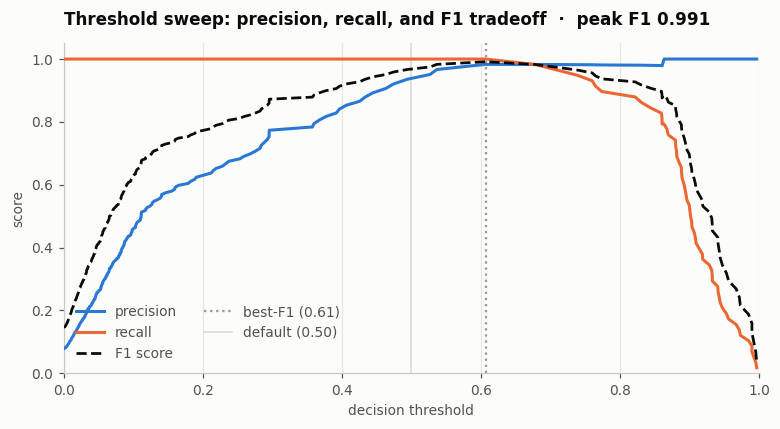

,precision,recall,missed_cases,false_alarms
threshold,,,,
0.1,0.4603,1.0000,0,68
0.2,0.6304,1.0000,0,34
0.3,0.7838,1.0000,0,16
0.4,0.8529,1.0000,0,10
0.5,0.9508,1.0000,0,3
0.6,0.9831,1.0000,0,1
0.7,0.9825,0.9655,2,1


In [15]:
f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
best = int(np.nanargmax(f1[:-1]))
best_thr = thr[best]
print(f"best-F1 threshold {best_thr:.3f}  ->  precision {prec[best]:.4f}  "
      f"recall {rec[best]:.4f}  F1 {f1[best]:.4f}")

fig, ax = plt.subplots(figsize=(7.2, 4.0))
ax.plot(thr, prec[:-1], label="precision", color=NEG, zorder=3)
ax.plot(thr, rec[:-1], label="recall", color=POS, zorder=3)
ax.plot(thr, f1[:-1], label="F1 score", color=INK, linestyle="--", lw=1.8, zorder=3)
ax.axvline(best_thr, color="#9a9992", linestyle=":", linewidth=1.5,
           label=f"best-F1 ({best_thr:.2f})", zorder=2)
ax.axvline(0.5, color="#c9c8c3", linestyle="-", linewidth=1.0, alpha=0.7,
           label="default (0.50)", zorder=2)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.set_xlabel("decision threshold")
ax.set_ylabel("score")
ax.set_title(f"Threshold sweep: precision, recall, and F1 tradeoff  ·  peak F1 {f1[best]:.3f}")
ax.legend(loc="lower left", ncol=2)
ax.grid(axis="both")
ax.spines["bottom"].set_color("#c9c8c3")
ax.spines["left"].set_color("#c9c8c3")
plt.tight_layout()
plt.show()

sweep = pd.DataFrame([
    {"threshold": t,
     "precision": (p := ((proba >= t) & (y_test == 1)).sum() / max(((proba >= t).sum()), 1)),
     "recall": (r := ((proba >= t) & (y_test == 1)).sum() / (y_test == 1).sum()),
     "missed_cases": int(((proba < t) & (y_test == 1)).sum()),
     "false_alarms": int(((proba >= t) & (y_test == 0)).sum())}
    for t in [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70]
]).set_index("threshold").round(4)
sweep

## 8. Which features matter

Permutation importance on the **test** set, scored by average precision. Preferred over the
forest's built-in Gini importance, which inflates high-cardinality continuous features.

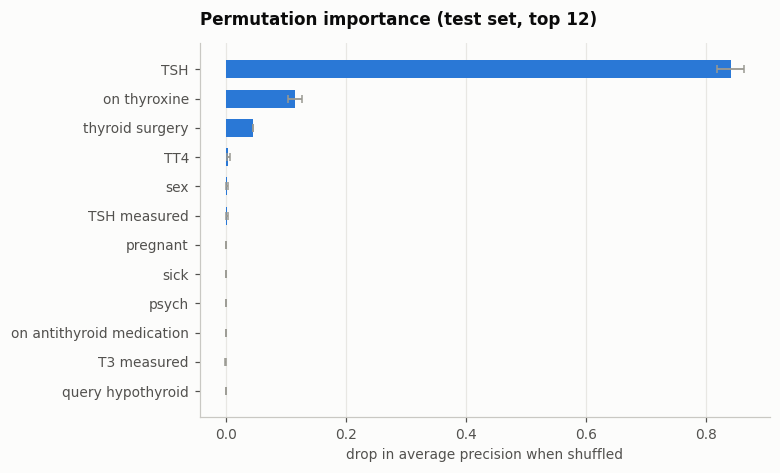

,mean,std
TSH,0.84046,0.02218
on thyroxine,0.11470,0.01189
thyroid surgery,0.04491,0.00000
TT4,0.00399,0.00202
sex,0.00240,0.00163
TSH measured,0.00122,0.00141
pregnant,0.00021,0.00052
sick,0.00020,0.00025
psych,0.00019,0.00037
on antithyroid medication,0.00016,0.00065


In [16]:
pi = permutation_importance(
    rf, X_test, y_test, n_repeats=20, random_state=RANDOM_STATE,
    scoring="average_precision", n_jobs=-1,
)
imp = pd.DataFrame({"mean": pi.importances_mean, "std": pi.importances_std},
                   index=X_test.columns).sort_values("mean", ascending=False)

top = imp.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.2, 4.4))
ax.barh(top.index, top["mean"], xerr=top["std"], height=0.62, color=NEG, zorder=3,
        error_kw=dict(ecolor="#9a9992", lw=1.2, capsize=2.5))
ax.set_xlabel("drop in average precision when shuffled")
ax.set_title("Permutation importance (test set, top 12)")
ax.grid(axis="x", zorder=0)
ax.grid(axis="y", visible=False)
ax.spines["left"].set_color("#c9c8c3")
plt.tight_layout()
plt.show()

imp.head(12).round(5)

## 9. Is the model actually doing anything? An ablation

Average precision of 0.996 and recall of 1.00 should prompt suspicion, not satisfaction. The
permutation importance above is dominated by a single feature, TSH, so the obvious question is
whether the forest has learned anything beyond the textbook diagnostic rule.

Two facts sharpen the question:

- **Every hypothyroid row in this dataset has a TSH measurement.** None are missing. You cannot be
  labelled hypothyroid here without the test that defines it.
- **A single hand-written threshold, `TSH >= 6`, already reaches 0.993 recall** at 0.777 precision.

So the label is close to a deterministic function of TSH and T4 -- which is expected, because the
diagnoses in the source UCI data were assigned by clinicians applying exactly that rule to exactly
these lab values. The comparison below is the honest one: not model vs. chance, but model vs. the
rule it is rediscovering, and model vs. itself with the giveaway features removed.

In [17]:
def score(cols, label):
    m = RandomForestClassifier(n_estimators=500, min_samples_leaf=2, class_weight="balanced",
                               random_state=RANDOM_STATE, n_jobs=-1)
    m.fit(X_train[cols], y_train)
    p = m.predict_proba(X_test[cols])[:, 1]
    pr, rc, _ = precision_recall_curve(y_test, p)
    f = 2 * pr * rc / np.clip(pr + rc, 1e-12, None)
    b = int(np.nanargmax(f[:-1]))
    return {"variant": label, "n_features": len(cols),
            "avg_precision": round(average_precision_score(y_test, p), 4),
            "roc_auc": round(roc_auc_score(y_test, p), 4),
            "precision@bestF1": round(pr[b], 4), "recall@bestF1": round(rc[b], 4)}

# Features that presuppose a prior thyroid diagnosis or referral suspicion.
CIRCULAR = ["on thyroxine", "query on thyroxine", "on antithyroid medication", "thyroid surgery",
            "I131 treatment", "query hypothyroid", "query hyperthyroid"]
all_cols = list(X_train.columns)

results = [
    score(all_cols, "full model"),
    score([c for c in all_cols if c != "TSH"], "no TSH"),
    score([c for c in all_cols if c not in CIRCULAR], "no referral/treatment flags"),
    score([c for c in all_cols if c != "TSH" and c not in CIRCULAR], "neither"),
    score(["TSH"], "TSH alone"),
]

# The hand-written clinical rule, for reference.
rule = (X_test["TSH"].fillna(0) >= 6).astype(int)
tp = int(((rule == 1) & (y_test == 1)).sum())
results.append({"variant": "rule: TSH >= 6", "n_features": 1, "avg_precision": np.nan,
                "roc_auc": np.nan,
                "precision@bestF1": round(tp / max(int((rule == 1).sum()), 1), 4),
                "recall@bestF1": round(tp / int((y_test == 1).sum()), 4)})

pd.DataFrame(results).set_index("variant")

,n_features,avg_precision,roc_auc,precision@bestF1,recall@bestF1
variant,,,,,
full model,24,0.9961,0.9997,0.9831,1.0000
no TSH,23,0.3603,0.7390,0.5278,0.3276
no referral/treatment flags,17,0.8443,0.9899,0.7632,1.0000
neither,16,0.3265,0.7157,0.4043,0.3276
TSH alone,1,0.8064,0.9889,0.7532,1.0000
rule: TSH >= 6,1,NaN,NaN,0.7342,1.0000


### What the ablation says

- **TSH is necessary but not sufficient.** Strip it and average precision collapses from 0.996 to 0.360, with recall falling to 0.33 -- so the headline score does rest on that one feature. But TSH *alone* reaches only 0.806 average precision, and 0.753 precision at full recall, so the forest is not merely echoing it.
- **The precision gain over the hand-written rule is the forest's real contribution.** At full recall
  the `TSH >= 6` rule holds 0.734 precision and the forest holds 0.983 -- roughly 20 false alarms
  cut to 1, on 742 patients. It buys that by reading TT4, FTI and `on thyroxine` alongside TSH,
  clearing out patients already on thyroxine replacement, who are *treated* and therefore labelled
  negative despite abnormal labs.
- **Without TSH** performance drops materially, and that number is the better estimate of value on
  a patient whose TSH has not been run -- which, in this dataset, never happens for a positive case.

### Caveat to carry forward

`on thyroxine` ranks second in importance, and it is circular: being on thyroid hormone
replacement means hypothyroidism was already diagnosed, by someone else, earlier. The model uses
it mainly to *rule out* -- 13.1% of negatives are on thyroxine versus 3.1% of hypothyroid cases.

So these scores describe **a model that reproduces a lab-based diagnostic rule on an
already-referred population**. They are not an estimate of screening performance on the general
public, where the prevalence is lower, TSH is often not ordered, and treatment history is absent.
The "neither" row above is the pessimistic bound, and it is the number to quote for that use case.

## 10. Summary

- Target is binary, negative vs hypothyroid, at 7.7% positives. The brief's hyperthyroid class is
  not in this file and cannot be recovered from it.
- The "cleaned" CSV had mean-imputed fills marked by the `measured` flags. Those were reversed to
  `NaN` and handled natively by the forest, which also removed a train/test leak of global means.
- 63 duplicate rows dropped before splitting; `hypopituitary` dropped as near-constant.
- The 500-tree balanced forest reaches ~0.95 precision at 1.00 recall on the held-out set, but the
  ablation shows this is largely TSH, by construction of the labels.
- The defensible claim is narrow: the model recovers the clinical rule and improves its precision
  by using T4 and treatment history. Anything stronger needs a dataset where the label was not
  derived from the features.